# Stacking Ensemble:

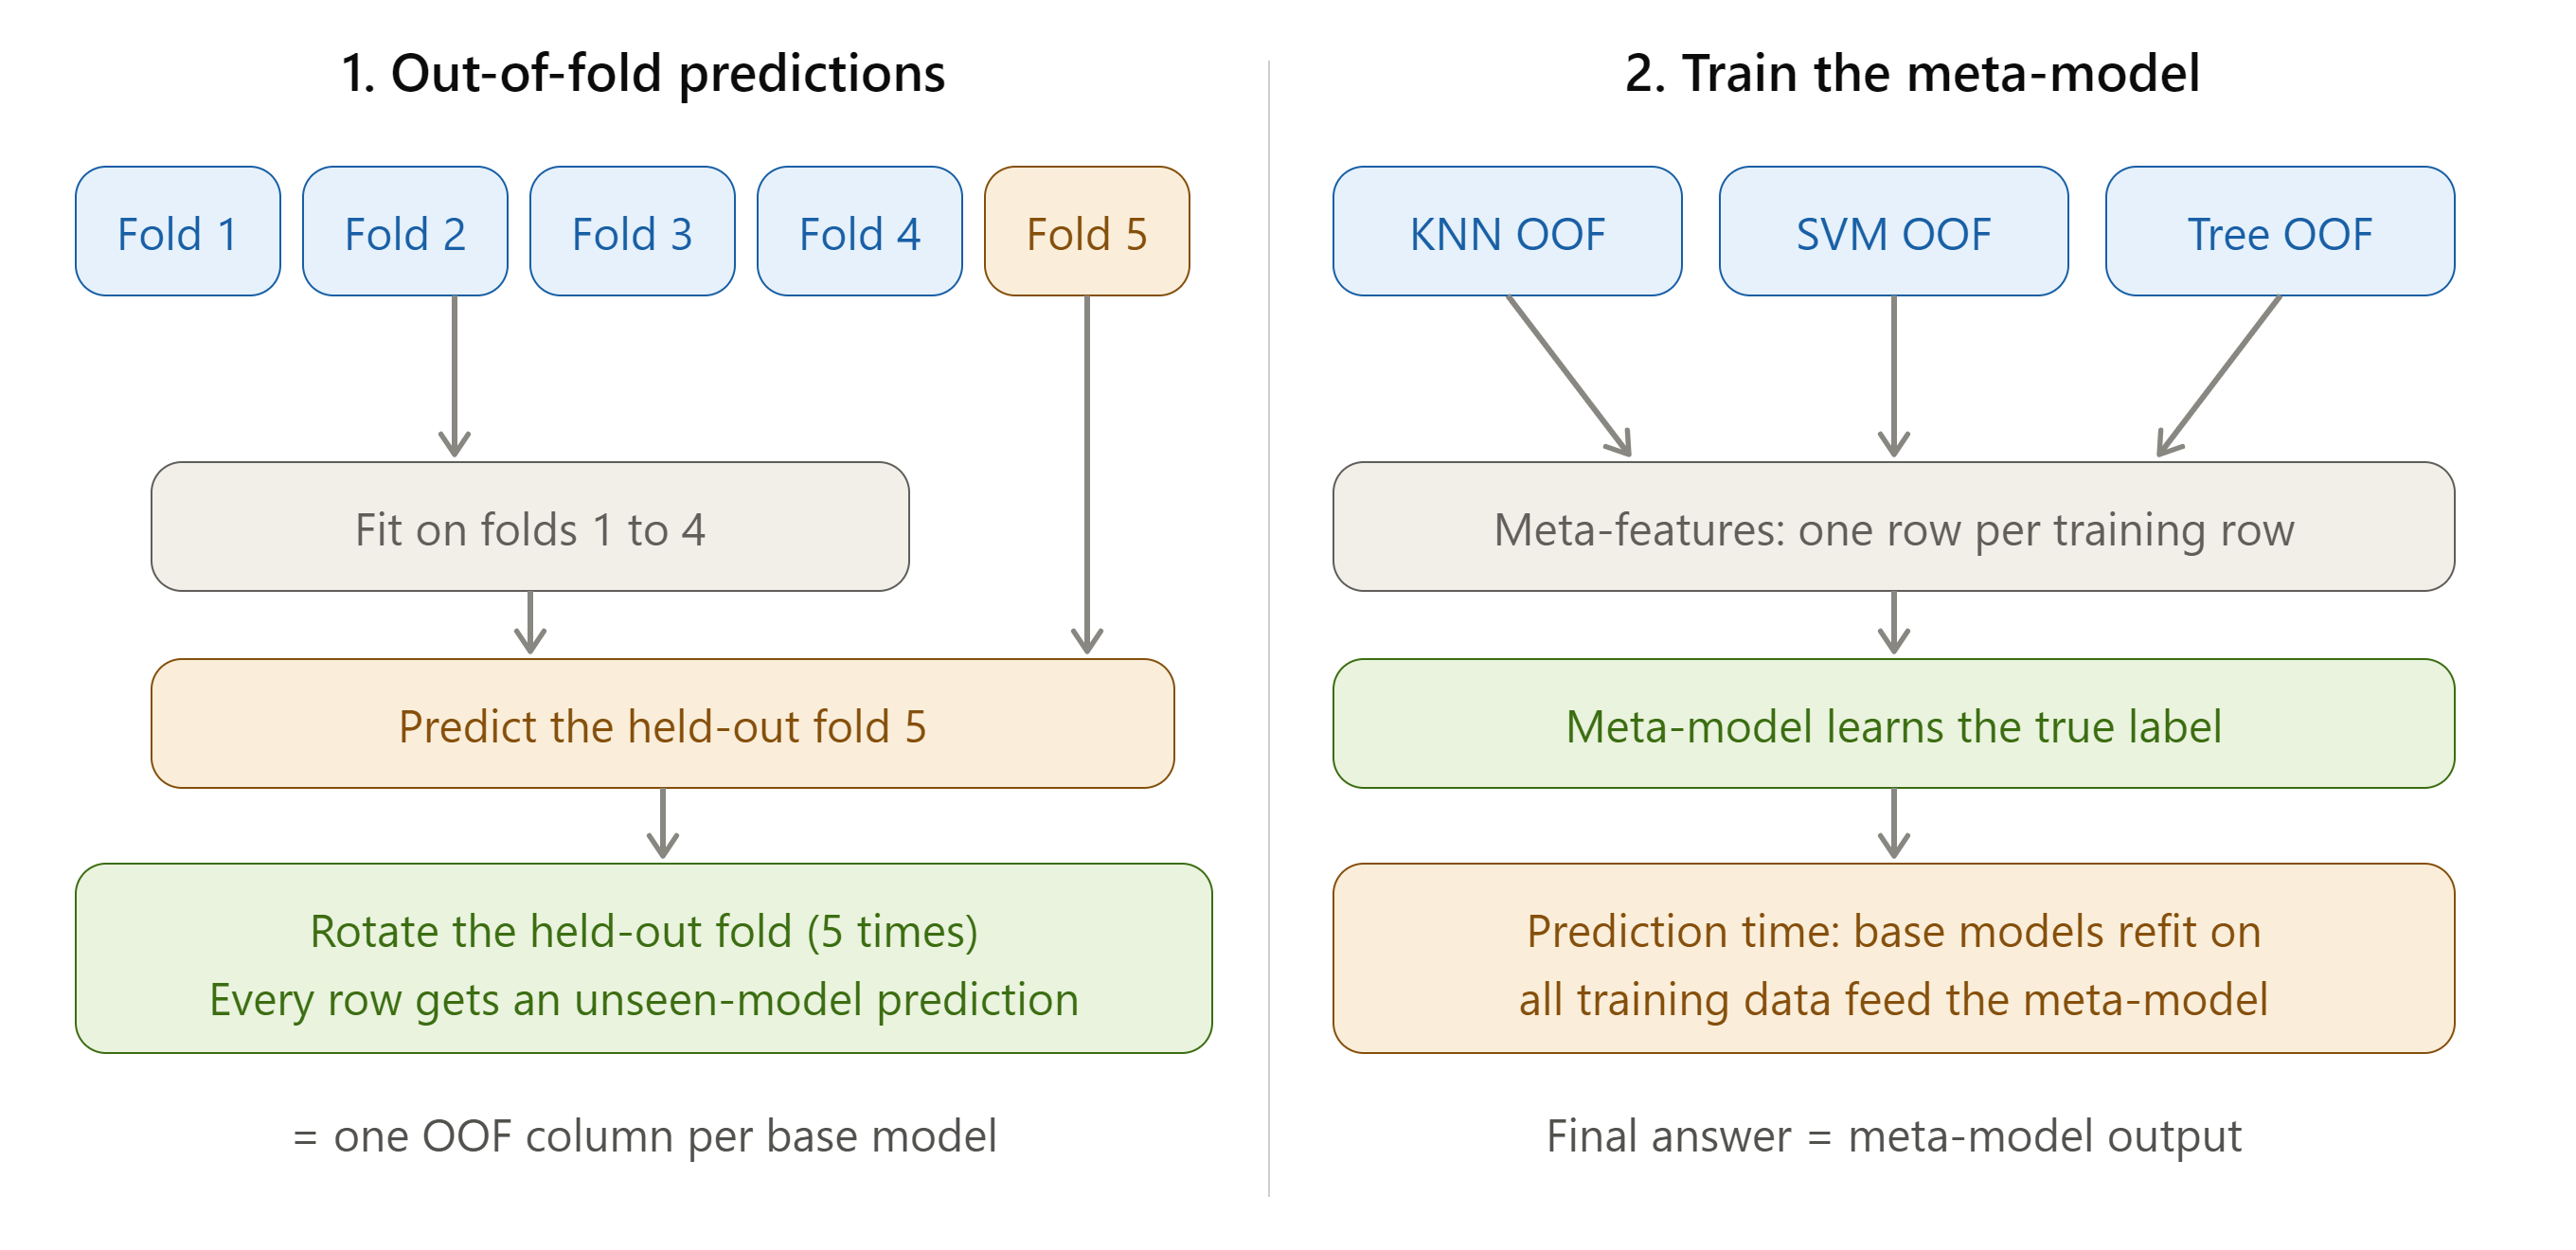

The meta-feature matrix Z has one row per training row and one column per base model (or several columns per model for classification). Entry Z[i, m] is the prediction for row i from model m, trained without row i's fold.

## 1. The full algorithm:

1. Split the training data into k folds (stratified for classification).
2. For each base model, produce OOF predictions for every training row, as in the diagram.
3. Stack those columns into the meta-feature table Z.
4. Train the meta-learner on Z with the true labels as the target.
5. Refit every base model on the **entire** training set.
6. For a new row, get each refit base model's prediction, then feed those predictions to the meta-learner.

Some implementations skip step 5 and average the k fold-models' predictions on new data instead. scikit-learn refits.

## 2. Choosing the base learners:

- **Diversity matters more than individual strength.** If all base models make the same mistakes, the meta-learner has nothing to work with. Mix different families: a linear model, a tree ensemble, KNN, SVM, maybe a neural network.
- **Each model should be reasonably good.** A near-random model adds noise.
- **Check diversity directly** by looking at the correlation between the OOF prediction columns. Very high correlation means a model adds little.

## 3. Choosing the meta-learner:

- **Keep it simple and regularized.** Logistic regression for classification, and ridge or lasso for regression, are the usual defaults. The meta-features are already strong signals, so a flexible meta-model mostly overfits them.
- A **linear meta-model is directly interpretable**: its coefficients are the learned weights of each base model. Weighted averaging is essentially a special case.
- For classification, feed it **predicted probabilities**, not hard labels. Probabilities carry confidence, and labels throw it away. For K classes and M models, that gives about M × K columns. scikit-learn drops one column for binary problems, since the two probabilities sum to 1.
- **Passthrough** (`passthrough=True`) also gives the meta-learner the original features. It can help, but it makes overfitting easier.

## 4. Related methods:

| Method | How the combination is decided | Training data for the combiner |
|---|---|---|
| Voting / averaging | Fixed rule (equal weights) | None |
| Blending | Learned meta-model | A single hold-out set |
| Stacking | Learned meta-model | Out-of-fold predictions on all training data |

- **Blending** is simpler and avoids some leakage mistakes, but it wastes data: the base models never train on the hold-out set, and the meta-model sees only that small set.
- **Multi-level stacking** adds a third level (a meta-meta-learner). Gains shrink quickly and complexity grows, so it is rare outside competitions.

## 5. scikit-learn:

```python
from sklearn.ensemble import StackingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

base_models = [
    ("knn", make_pipeline(StandardScaler(), KNeighborsClassifier())),
    ("svm", make_pipeline(StandardScaler(), SVC(probability=True, random_state=42))),
    ("rf", RandomForestClassifier(random_state=42)),
]

stack = StackingClassifier(
    estimators=base_models,
    final_estimator=LogisticRegression(),
    cv=5,
    stack_method="predict_proba",
    passthrough=False,
    n_jobs=-1,
)
stack.fit(X_train, y_train)
print(stack.score(X_test, y_test))
```

Key parameters:

| Parameter | Meaning |
|---|---|
| `estimators` | List of (name, model) base learners |
| `final_estimator` | The meta-learner. Defaults to logistic regression (classifier) or `RidgeCV` (regressor) |
| `cv` | Folds used to create the OOF predictions (default 5) |
| `stack_method` | What each base model outputs. `"auto"` tries `predict_proba`, then `decision_function`, then `predict` |
| `passthrough` | Also give the meta-learner the original features |

`StackingRegressor` works the same way. Calling `stack.transform(X)` returns the meta-features, which is useful for checking how correlated the base models are.

## 6. Strengths and weaknesses:

**Strengths**
- It often beats both the best single model and a plain vote, since it learns where each model is reliable.
- It can combine completely different model types.
- It is flexible: any model can serve at either level.

**Weaknesses**
- **Cost:** each base model is trained k + 1 times, and prediction runs every base model plus the meta-model.
- **Complexity:** harder to deploy, debug and explain than one model.
- **Overfitting risk on small datasets,** where the OOF predictions are noisy.
- **Diminishing returns** if the base models are similar, or if one model already dominates.
- **Time series:** scikit-learn's stacking needs CV folds that partition the data, so time-ordered splits like `TimeSeriesSplit` don't work directly. You need extra care to avoid using the future to predict the past.

## 7. Practical tips:

- Use the same stratified folds for all base models.
- Evaluate the final stack on a held-out test set that nothing in the pipeline has touched. Never tune the meta-learner on that test set.
- Compare against the best single base model and against a simple voting ensemble. If stacking doesn't beat those clearly, use the simpler one.
- Scale features inside the base models' pipelines where needed (KNN and SVM), not on the meta-features.

---